# Simple Test

Two experiments on a single 35+35 solar mass binary with every parameter frozen except one.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src')); sys.path.insert(0, str(ROOT / 'examples'))
import numpy as np
import matplotlib.pyplot as plt
from exmarg import figstyle; figstyle.apply()
get_ipython().run_line_magic("matplotlib","inline")
from motivation_engine import Motivation

M = Motivation('data/motivation_inputs.npz')
print('frozen 35+35 template: %d frequency bins, T = %.0f s' % (M.f.size, M.T))

/projects/standard/vuk/shared/boyb001/non_gaussian/exmarg/src/exmarg/profiles.py:14: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


frozen 35+35 template: 586 frequency bins, T = 6 s


## Figure 1. The single parameter experiment (arrival time)

Slide the filter arrival time across a signal injected at a true arrival time and read the log likelihood ratio.


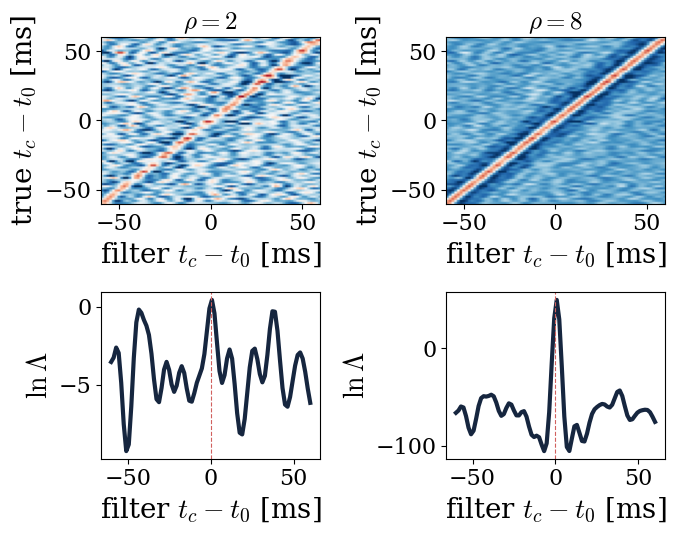

In [2]:
t0, half, Ncell = M.T / 2, 0.06, 80
grid = np.linspace(t0 - half, t0 + half, Ncell)
NAVY, RED = figstyle.NAVY, figstyle.RED

fig, ax = plt.subplots(2, 2, figsize=(7.0, 5.6))
mats = {}
for col, rho in enumerate([2.0, 8.0]):
    Mtx = M.build_tc_matrix(rho, grid, grid); mats[rho] = Mtx
    v = np.percentile(np.abs(Mtx), 99)
    ax[0, col].imshow(Mtx, origin='lower', aspect='auto', cmap='RdBu_r',
                      vmin=-v, vmax=v,
                      extent=[(grid[0]-t0)*1e3, (grid[-1]-t0)*1e3,
                              (grid[0]-t0)*1e3, (grid[-1]-t0)*1e3])
    ax[0, col].set_title(r'$\rho = %g$' % rho)
    ax[0, col].set_xlabel(r'filter $t_c - t_0$ [ms]')
    ax[0, col].set_ylabel(r'true $t_c - t_0$ [ms]')
    ax[1, col].plot((grid - t0) * 1e3, Mtx[Ncell // 2], color=NAVY)
    ax[1, col].axvline(0, color=RED, lw=0.8, ls='--')
    ax[1, col].set_xlabel(r'filter $t_c - t_0$ [ms]')
    ax[1, col].set_ylabel(r'$\ln\Lambda$')
fig.tight_layout()
np.savez('data/fig1_tc_matrix.npz', grid=grid, t0=t0,
         M_rho2=mats[2.0], M_rho8=mats[8.0])
plt.show()

## Figure 2. Eigenspectrum of the single event kernel

The noise-averaged covariance of the likelihood ratio over the frozen parameter has an eigenspectrum whose effective rank is the number of resolved cells.


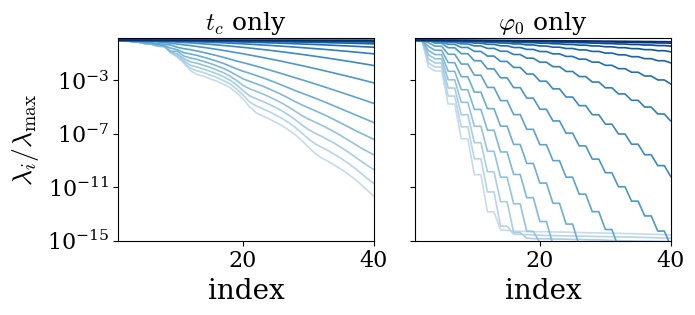

In [3]:
rhos = np.logspace(np.log10(0.1), np.log10(16.0), 16)
cmap = plt.cm.Blues
from matplotlib.colors import LogNorm
norm = LogNorm(rhos[0], rhos[-1])

fig, ax = plt.subplots(1, 2, figsize=(7.2, 3.4), sharey=True)
spec = {}
for j, kind in enumerate(['tc', 'phic']):
    sv = [M.spectrum(r, kind=kind) for r in rhos]; spec[kind] = np.array(sv)
    for r, s in zip(rhos, sv):
        ax[j].plot(np.arange(1, s.size + 1), s, lw=1.2,
                   color=cmap(0.25 + 0.75 * norm(r)))
    ax[j].set_yscale('log'); ax[j].set_ylim(1e-15, 1.4)
    ax[j].set_xlim(1, 40)
    ax[j].set_xlabel('index')
    ax[j].set_title(r'$t_c$ only' if kind == 'tc' else r'$\varphi_0$ only')
ax[0].set_ylabel(r'$\lambda_i / \lambda_{\max}$')
fig.tight_layout()
np.savez('data/fig2_svd.npz', rhos=rhos, sv_tc=spec['tc'], sv_phic=spec['phic'])
plt.show()